# EDA các tập dữ liệu trong `dataset/`

Notebook phân tích khám phá (EDA) cho 3 bộ dữ liệu dùng trong Jigsaw Attack:

| Bộ dữ liệu | File | Cấu trúc |
|---|---|---|
| Enron | `enron_db.pkl` | `[docs, kws_dict]` — `docs`: list tài liệu, mỗi tài liệu là list keyword; `kws_dict[kw] = {"count", "trend"}` |
| Lucene | `lucene_db.pkl` | giống Enron |
| Wikipedia | `wiki_doc_0.pkl` + `wiki_kws_dict.pkl` | docs và kws_dict tách thành 2 file |

- `count`: số tài liệu chứa keyword (= **volume** của keyword khi bị truy vấn).
- `trend`: chuỗi tần suất truy vấn theo tuần (Google Trends) — prior knowledge về **frequency** mà kẻ tấn công dùng.

Mọi hình được lưu vào `eda_results/`.

In [1]:
import pickle, struct, time, itertools
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
DATA_DIR = Path("dataset")
OUT_DIR = Path("eda_results"); OUT_DIR.mkdir(exist_ok=True)

# wiki_doc_0.pkl ~2.8GB: load toàn bộ cần >12GB RAM, nên chỉ đọc streaming N tài liệu đầu
WIKI_DOC_SAMPLE = 50_000

def savefig(name):
    plt.tight_layout(); plt.savefig(OUT_DIR / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()

## 1. Load dữ liệu

In [2]:
def stream_wiki_docs(path, max_docs):
    """Đọc N tài liệu đầu của pickle (protocol 3, list[list[str]]) mà không load cả file."""
    MARK = object(); memo = {}; stack = []; outer = None
    with open(path, "rb") as f:
        rd = f.read
        assert rd(2) == b"\x80\x03", "chỉ hỗ trợ pickle protocol 3"
        while True:
            op = rd(1)
            if op == b"]":                       # EMPTY_LIST
                stack.append([])
                if outer is None: outer = stack[-1]
            elif op == b"(": stack.append(MARK)  # MARK
            elif op == b"X":                     # BINUNICODE
                n = struct.unpack("<I", rd(4))[0]; stack.append(rd(n).decode("utf-8", "surrogatepass"))
            elif op == b"q": memo[rd(1)[0]] = stack[-1]                         # BINPUT
            elif op == b"r": memo[struct.unpack("<I", rd(4))[0]] = stack[-1]    # LONG_BINPUT
            elif op == b"h": stack.append(memo[rd(1)[0]])                       # BINGET
            elif op == b"j": stack.append(memo[struct.unpack("<I", rd(4))[0]])  # LONG_BINGET
            elif op == b"e":                     # APPENDS
                i = len(stack) - 1
                while stack[i] is not MARK: i -= 1
                items = stack[i + 1:]; del stack[i:]; stack[-1].extend(items)
                if stack[-1] is outer and len(outer) >= max_docs: return outer[:max_docs]
            elif op == b"a":                     # APPEND
                x = stack.pop(); stack[-1].append(x)
                if stack[-1] is outer and len(outer) >= max_docs: return outer[:max_docs]
            elif op == b".": return outer        # STOP
            else: raise ValueError(f"opcode {op!r} tại byte {f.tell()}")

datasets = {}
for name, fn in [("enron", "enron_db.pkl"), ("lucene", "lucene_db.pkl")]:
    t = time.time()
    with open(DATA_DIR / fn, "rb") as f:
        docs, kws = pickle.load(f)
    datasets[name] = {"docs": docs, "kws": kws, "docs_complete": True}
    print(f"{name:7s}: {len(docs):>7,} docs, {len(kws):>7,} keywords  ({time.time()-t:.1f}s)")

t = time.time()
with open(DATA_DIR / "wiki_kws_dict.pkl", "rb") as f:
    wiki_kws = pickle.load(f)
wiki_docs = stream_wiki_docs(DATA_DIR / "wiki_doc_0.pkl", WIKI_DOC_SAMPLE)
datasets["wiki"] = {"docs": wiki_docs, "kws": wiki_kws, "docs_complete": len(wiki_docs) < WIKI_DOC_SAMPLE}
print(f"wiki   : {len(wiki_docs):>7,} docs (mẫu), {len(wiki_kws):>7,} keywords  ({time.time()-t:.1f}s)")

enron  :  30,109 docs,   3,000 keywords  (0.2s)


lucene :  66,491 docs,   3,000 keywords  (0.4s)


wiki   :  50,000 docs (mẫu), 509,480 keywords  (17.9s)


## 2. Tổng quan

In [3]:
rows = []
for name, d in datasets.items():
    docs, kws = d["docs"], d["kws"]
    lens = np.array([len(x) for x in docs])
    vocab_in_docs = set(itertools.chain.from_iterable(docs))
    rows.append({
        "dataset": name,
        "#docs (đã đọc)": len(docs),
        "docs đầy đủ?": d["docs_complete"],
        "#keywords trong kws_dict": len(kws),
        "#keyword phân biệt trong docs": len(vocab_in_docs),
        "keyword trong docs ∉ kws_dict": len(vocab_in_docs - kws.keys()),
        "TB keyword/doc": lens.mean().round(2),
        "median keyword/doc": np.median(lens),
        "max keyword/doc": lens.max(),
        "#doc rỗng": int((lens == 0).sum()),
        "#doc có keyword lặp": sum(len(x) != len(set(x)) for x in docs),
        "độ dài trend (tuần)": len(next(iter(kws.values()))["trend"]),
    })
overview = pd.DataFrame(rows).set_index("dataset").T
overview.to_csv(OUT_DIR / "overview.csv")
overview

dataset,enron,lucene,wiki
#docs (đã đọc),30109,66491,50000
docs đầy đủ?,True,True,False
#keywords trong kws_dict,3000,3000,509480
#keyword phân biệt trong docs,3000,3000,533371
keyword trong docs ∉ kws_dict,0,0,289885
TB keyword/doc,33.49,34.85,190.1
median keyword/doc,22.0,28.0,109.0
max keyword/doc,1215,458,5062
#doc rỗng,546,1010,11
#doc có keyword lặp,0,0,0


**Nhận xét:** Enron và Lucene đã được tiền xử lý sẵn về vũ trụ 3.000 keyword; Wikipedia có kws_dict thô ~509K keyword và cần chạy `dataset/preprocess.py` để rút về top-k keyword. Trend của Enron/Lucene dài 260 tuần (~5 năm), Wikipedia chỉ có 75 tuần.

## 3. Kiểm tra tính nhất quán: `count` có phải là document frequency?

In [4]:
for name in ["enron", "lucene"]:
    docs, kws = datasets[name]["docs"], datasets[name]["kws"]
    df = Counter(w for doc in docs for w in set(doc))
    match = np.mean([df[k] == v["count"] for k, v in kws.items()])
    print(f"{name}: tỉ lệ keyword có count == số doc chứa keyword: {match:.2%}")

enron: tỉ lệ keyword có count == số doc chứa keyword: 100.00%


lucene: tỉ lệ keyword có count == số doc chứa keyword: 100.00%


`count` chính là số tài liệu chứa keyword, tức **volume** (kích thước response) mà server lộ ra khi keyword đó được truy vấn.

## 4. Phân bố số keyword trên mỗi tài liệu

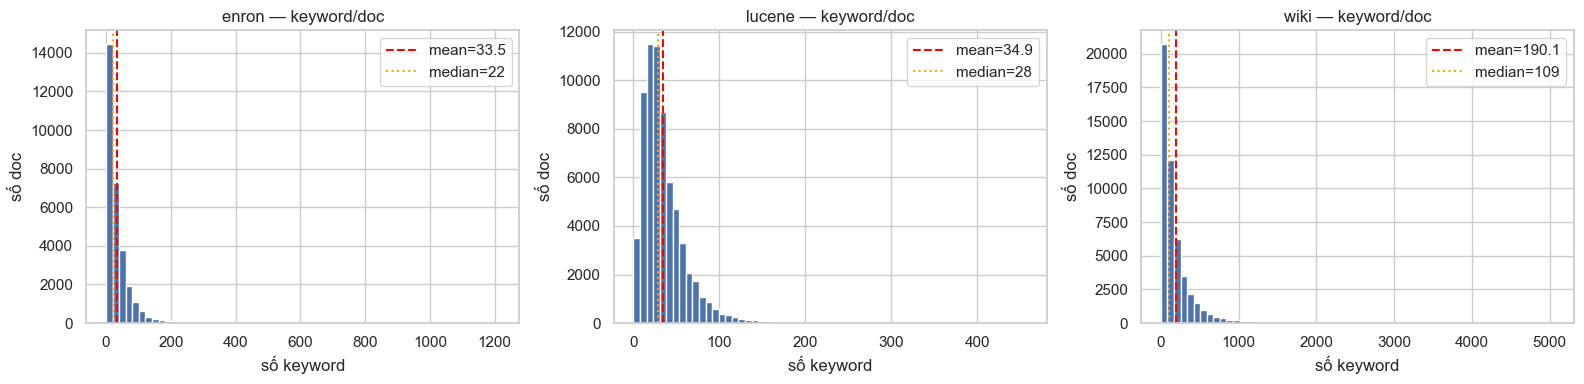

,enron,lucene,wiki
count,30109.00,66491.00,50000.00
mean,33.49,34.85,190.10
std,39.13,25.99,250.04
min,0.00,0.00,0.00
25%,9.00,18.00,49.00
50%,22.00,28.00,109.00
75%,44.00,45.00,227.00
90%,76.00,66.00,438.00
99%,181.00,129.00,1233.01
max,1215.00,458.00,5062.00


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, d) in zip(axes, datasets.items()):
    lens = np.array([len(x) for x in d["docs"]])
    ax.hist(lens, bins=60, color="#4C72B0")
    ax.axvline(lens.mean(), color="red", ls="--", label=f"mean={lens.mean():.1f}")
    ax.axvline(np.median(lens), color="orange", ls=":", label=f"median={np.median(lens):.0f}")
    ax.set_title(f"{name} — keyword/doc"); ax.set_xlabel("số keyword"); ax.set_ylabel("số doc"); ax.legend()
savefig("doc_length_hist")

pd.DataFrame({n: pd.Series([len(x) for x in d["docs"]]).describe(percentiles=[.25, .5, .75, .9, .99])
              for n, d in datasets.items()}).round(2)

## 5. Phân bố volume (count) của keyword — luật Zipf

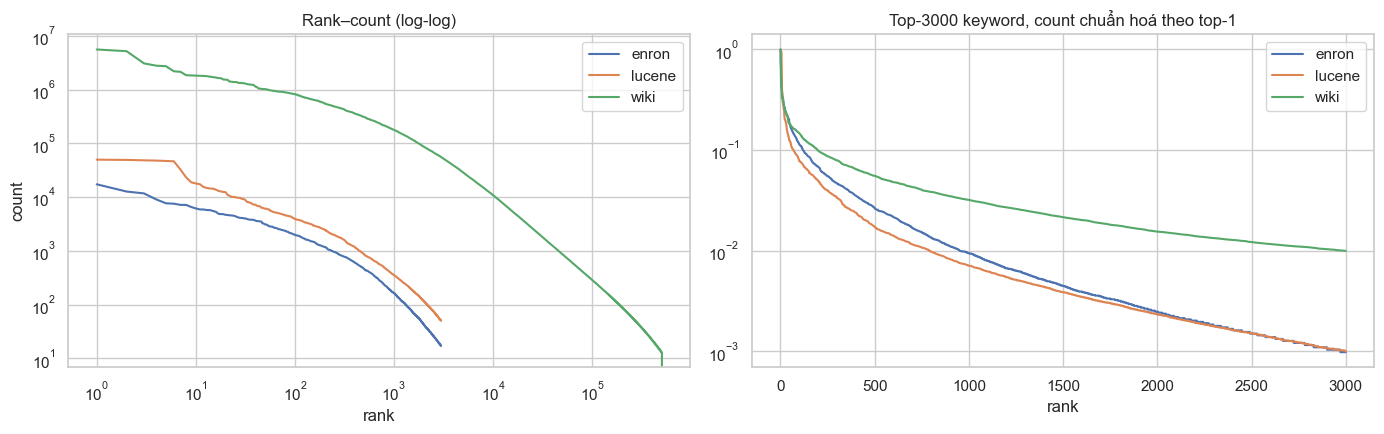

enron  : hệ số Zipf (top-3000) ≈ 1.34
lucene : hệ số Zipf (top-3000) ≈ 1.24
wiki   : hệ số Zipf (top-3000) ≈ 0.76


In [6]:
counts = {n: np.sort([v["count"] for v in d["kws"].values()])[::-1] for n, d in datasets.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n, c in counts.items():
    axes[0].loglog(np.arange(1, len(c) + 1), c, label=n)
axes[0].set_title("Rank–count (log-log)"); axes[0].set_xlabel("rank"); axes[0].set_ylabel("count"); axes[0].legend()
for n, c in counts.items():
    c = c[:3000]; axes[1].plot(np.arange(1, len(c) + 1), c / c[0], label=n)
axes[1].set_yscale("log"); axes[1].set_title("Top-3000 keyword, count chuẩn hoá theo top-1")
axes[1].set_xlabel("rank"); axes[1].legend()
savefig("keyword_count_zipf")

for n, c in counts.items():
    k = min(len(c), 3000); r = np.arange(1, k + 1)
    slope = np.polyfit(np.log(r), np.log(c[:k]), 1)[0]
    print(f"{n:7s}: hệ số Zipf (top-{k}) ≈ {-slope:.2f}")

In [7]:
pd.DataFrame({n: pd.Series(c).describe(percentiles=[.25, .5, .75, .9, .99]) for n, c in counts.items()}).round(1)

,enron,lucene,wiki
count,3000.0,3000.0,509480.0
mean,336.1,772.4,1889.5
std,844.6,2677.9,26808.1
min,17.0,50.0,0.0
25%,33.0,92.0,25.0
50%,77.5,193.0,57.0
75%,264.2,535.2,195.0
90%,809.1,1671.8,847.0
99%,3998.7,9060.6,27930.3
max,17303.0,49758.0,5589434.0


In [8]:
# Wikipedia: kws_dict thô rất lớn — xem có bao nhiêu keyword vượt các ngưỡng count
c = counts["wiki"]
pd.Series({f"count ≥ {t:,}": int((c >= t).sum()) for t in [1, 2, 10, 100, 1_000, 10_000, 100_000]}, name="#keyword wiki")

count ≥ 1          509479
count ≥ 2          509479
count ≥ 10         509479
count ≥ 100        188710
count ≥ 1,000       45998
count ≥ 10,000      10613
count ≥ 100,000      1781
Name: #keyword wiki, dtype: int64

## 6. Top keyword theo volume

In [9]:
top = {}
for n, d in datasets.items():
    s = sorted(d["kws"].items(), key=lambda kv: -kv[1]["count"])[:20]
    top[n] = [f"{k} ({v['count']:,})" for k, v in s]
pd.DataFrame(top, index=range(1, 21))

,enron,lucene,wiki
1,"subject (17,303)","e (49,758)","category (5,589,434)"
2,"thank (12,696)","apache (49,189)","reference (5,196,860)"
3,"forward (11,712)","help (48,413)","also (3,079,969)"
4,"know (9,034)","user (47,804)","link (2,791,336)"
5,"would (7,671)","mail (47,073)","external (2,730,256)"
6,"ani (7,539)","additional (46,418)","first (2,198,708)"
7,"let (7,168)","wrote (32,611)","people (2,146,659)"
8,"get (7,144)","index (23,235)","new (1,855,509)"
9,"need (6,537)","search (18,849)","state (1,839,735)"
10,"wa (6,163)","use (17,948)","two (1,823,682)"


## 7. Tính duy nhất của volume

Tấn công dựa trên volume (như bước đầu của Jigsaw) nhận diện chính xác keyword khi volume của nó **duy nhất**. Ở đây xét vũ trụ top-k keyword theo count.

In [10]:
rows = []
for n, c in counts.items():
    for k in [500, 1000, 3000] + ([5000, 10000, 30000] if n == "wiki" else []):
        sub = c[:k]; vc = Counter(sub)
        rows.append({"dataset": n, "top-k": k,
                     "% keyword có volume duy nhất": 100 * sum(1 for x in sub if vc[x] == 1) / k,
                     "kích thước nhóm trùng volume lớn nhất": max(vc.values())})
uniq = pd.DataFrame(rows).round(2); uniq

,dataset,top-k,% keyword có volume duy nhất,kích thước nhóm trùng volume lớn nhất
0,enron,500,75.20,3
1,enron,1000,46.90,10
2,enron,3000,15.67,71
3,lucene,500,89.20,2
4,lucene,1000,60.80,6
5,lucene,3000,21.07,33
6,wiki,500,100.00,1
7,wiki,1000,100.00,1
8,wiki,3000,98.33,2
9,wiki,5000,96.18,3


Keyword volume cao gần như luôn duy nhất → dễ bị khôi phục; keyword ở đuôi (volume nhỏ) trùng nhau nhiều → đây là phần "hard" mà Jigsaw xử lý sau.

## 8. Trend truy vấn (frequency)

In [11]:
trends, trend_kw = {}, {}
for n, d in datasets.items():
    # với wiki chỉ lấy top-3000 keyword theo count (đúng như preprocess.py)
    items = sorted(d["kws"].items(), key=lambda kv: -kv[1]["count"])[:3000]
    trend_kw[n] = [k for k, _ in items]
    trends[n] = np.array([v["trend"] for _, v in items], dtype=float)   # (n_kw, n_week)

rows = []
for n, T in trends.items():
    m = T.mean(1); alive = m > 0          # bỏ keyword có trend toàn 0 khi tính CV
    rows.append({"dataset": n, "shape (kw × tuần)": T.shape, "% ô bằng 0": 100 * (T == 0).mean(),
                 "% keyword trend toàn 0": 100 * (T.sum(1) == 0).mean(),
                 "min": T.min(), "max": T.max(), "tổng/tuần (TB)": T.sum(0).mean(),
                 "CV theo thời gian (median)": np.median(T[alive].std(1) / m[alive])})
pd.DataFrame(rows).set_index("dataset").round(4)

,shape (kw × tuần),% ô bằng 0,% keyword trend toàn 0,min,max,tổng/tuần (TB),CV theo thời gian (median)
dataset,,,,,,,
enron,"(3000, 260)",13.4929,8.8667,0.0,0.1812,2.8527,0.1367
lucene,"(3000, 260)",18.9431,13.0333,0.0,0.1805,2.5999,0.1304
wiki,"(3000, 75)",0.3018,0.0000,0.0,2.2497,7.7935,0.3187


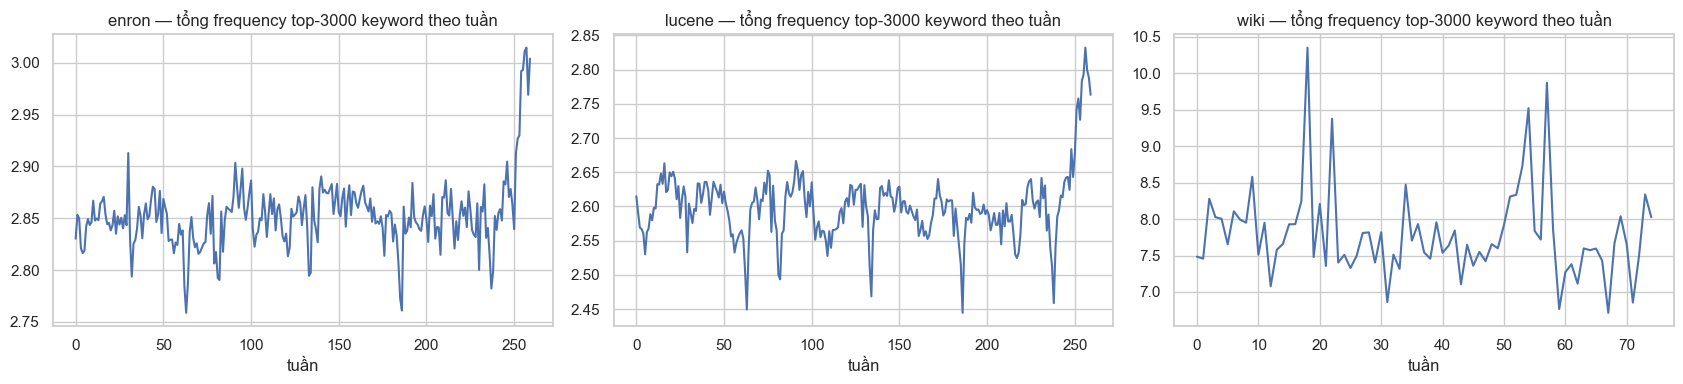

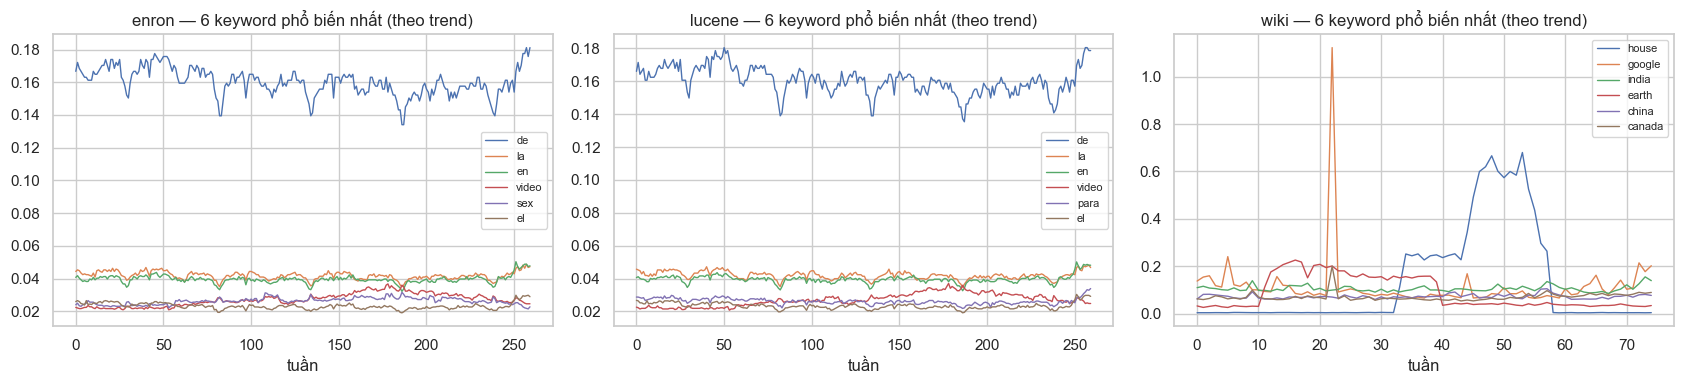

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (n, T) in zip(axes, trends.items()):
    ax.plot(T.sum(0), color="#4C72B0")
    ax.set_title(f"{n} — tổng frequency top-3000 keyword theo tuần"); ax.set_xlabel("tuần")
savefig("trend_total_per_week")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (n, T) in zip(axes, trends.items()):
    for i in np.argsort(-T.mean(1))[:6]:
        ax.plot(T[i], label=trend_kw[n][i], lw=1)
    ax.set_title(f"{n} — 6 keyword phổ biến nhất (theo trend)"); ax.set_xlabel("tuần"); ax.legend(fontsize=8)
savefig("trend_top_keywords")

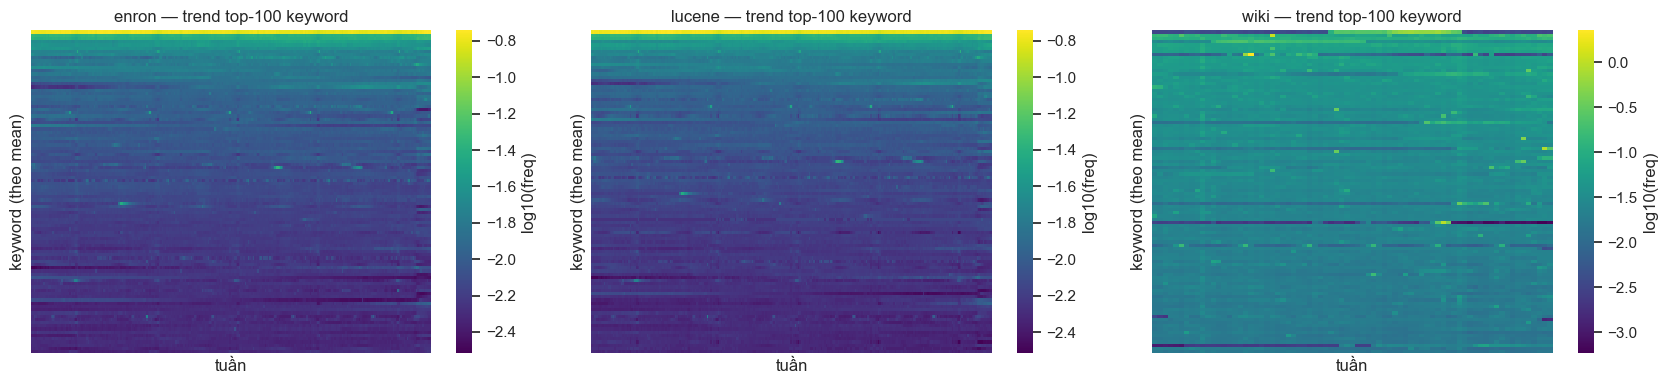

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (n, T) in zip(axes, trends.items()):
    order = np.argsort(-T.mean(1))[:100]
    sns.heatmap(np.log10(T[order] + 1e-6), ax=ax, cmap="viridis", cbar_kws={"label": "log10(freq)"})
    ax.set_title(f"{n} — trend top-100 keyword"); ax.set_xlabel("tuần"); ax.set_ylabel("keyword (theo mean)")
    ax.set_xticks([]); ax.set_yticks([])
savefig("trend_heatmap_top100")

### 8.1 Độ ổn định của trend theo thời gian

Kẻ tấn công dùng trend quá khứ làm prior; nếu phân bố frequency giữa các tuần cách xa nhau vẫn tương quan cao thì prior còn giá trị (liên quan thí nghiệm `test_durability.py`).

enron  : corr tuần 10 = 0.999, tuần giữa = 0.993, tuần cuối = 0.984, min = 0.957
lucene : corr tuần 10 = 0.999, tuần giữa = 0.994, tuần cuối = 0.986, min = 0.956
wiki   : corr tuần 10 = 0.960, tuần giữa = 0.759, tuần cuối = 0.826, min = 0.178


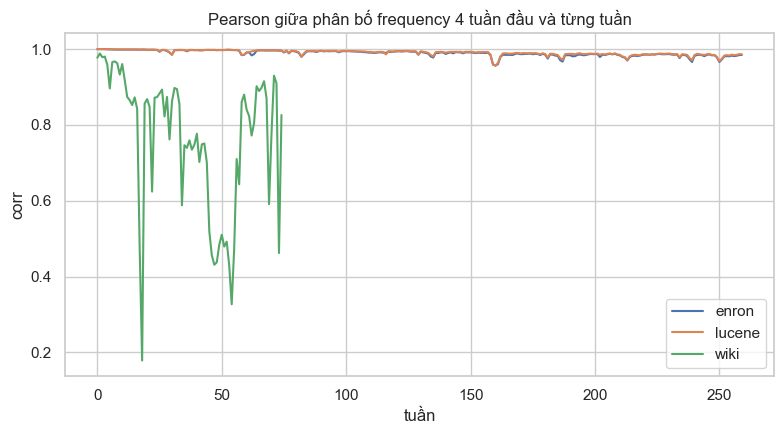

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for n, T in trends.items():
    P = T / np.maximum(T.sum(0, keepdims=True), 1e-12)        # phân bố frequency mỗi tuần
    base = P[:, :4].mean(1)                                   # 4 tuần đầu làm prior
    corr = [np.corrcoef(base, P[:, w])[0, 1] for w in range(T.shape[1])]
    ax.plot(corr, label=n)
    print(f"{n:7s}: corr tuần 10 = {corr[10]:.3f}, tuần giữa = {corr[len(corr)//2]:.3f}, tuần cuối = {corr[-1]:.3f}, min = {min(corr):.3f}")
ax.set_title("Pearson giữa phân bố frequency 4 tuần đầu và từng tuần"); ax.set_xlabel("tuần"); ax.set_ylabel("corr"); ax.legend()
savefig("trend_stability")

## 9. Quan hệ volume ↔ frequency

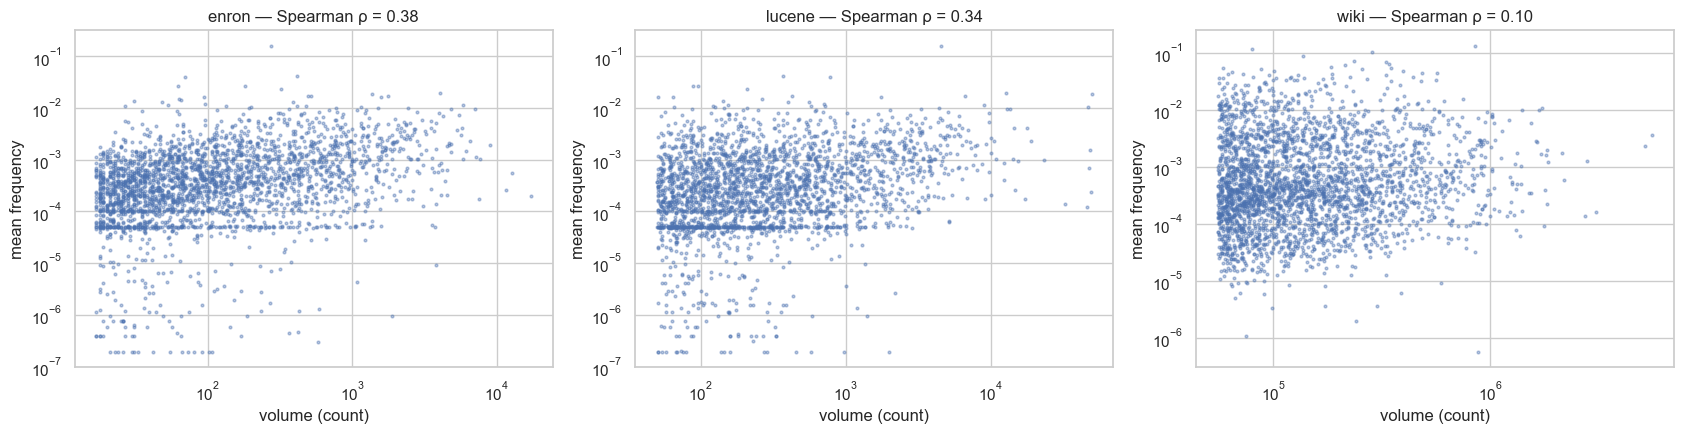

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (n, T) in zip(axes, trends.items()):
    vol = np.array([datasets[n]["kws"][k]["count"] for k in trend_kw[n]])
    freq = T.mean(1); ok = freq > 0
    ax.scatter(vol[ok], freq[ok], s=4, alpha=0.4)
    ax.set_xscale("log"); ax.set_yscale("log")
    rho = pd.Series(vol).corr(pd.Series(freq), method="spearman")
    ax.set_title(f"{n} — Spearman ρ = {rho:.2f}"); ax.set_xlabel("volume (count)"); ax.set_ylabel("mean frequency")
savefig("volume_vs_frequency")

Tương quan Spearman giữa volume và frequency chỉ ở mức yếu (Enron ≈ 0.38, Lucene ≈ 0.34, Wiki ≈ 0.10) → hai kênh rò rỉ mang thông tin bổ sung cho nhau, là lý do Jigsaw kết hợp cả hai.

## 10. Đồng xuất hiện keyword (co-occurrence)

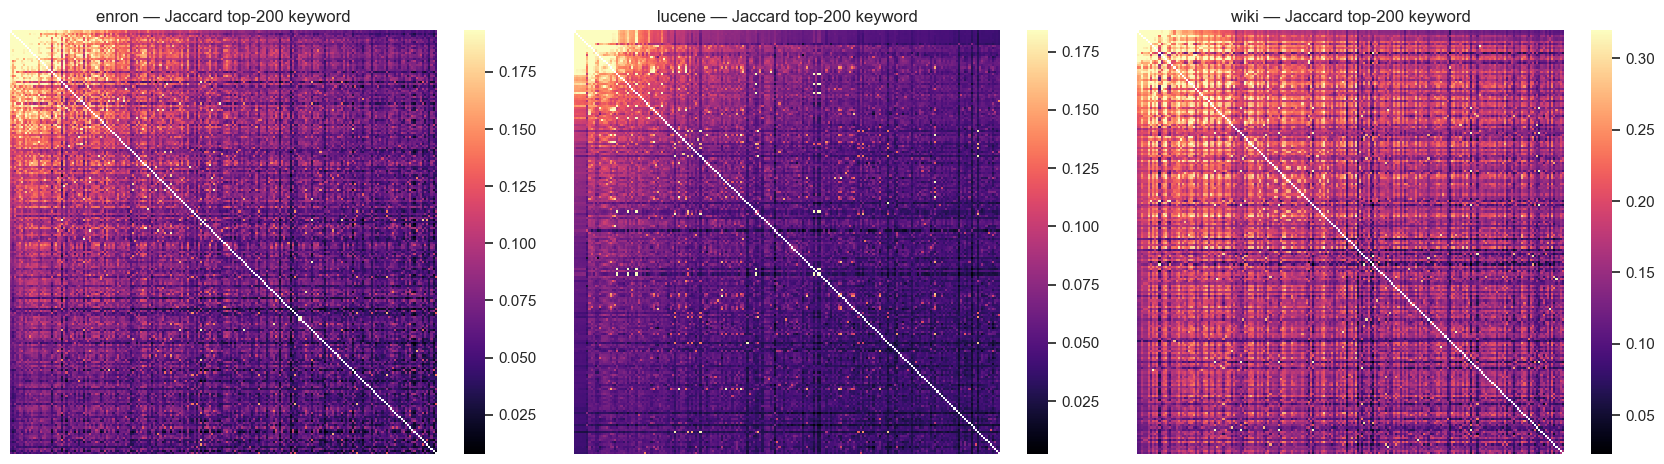

,% cặp có đồng xuất hiện,Jaccard TB,Jaccard max,% doc chứa ≥1 keyword top-K
dataset,,,,
enron,100.0,0.0773,0.6606,96.5891
lucene,100.0,0.0589,0.9777,98.4178
wiki,100.0,0.1674,0.9600,99.9700


In [16]:
def cooccurrence(docs, kw_list):
    idx = {k: i for i, k in enumerate(kw_list)}
    M = np.zeros((len(docs), len(kw_list)), dtype=np.float32)
    for r, doc in enumerate(docs):
        for w in doc:
            j = idx.get(w)
            if j is not None: M[r, j] = 1
    return M.T @ M, M

K = 200
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); co_stats = []
for ax, (n, d) in zip(axes, datasets.items()):
    kw_list = trend_kw[n][:K]
    co, M = cooccurrence(d["docs"], kw_list)
    vol = np.diag(co).copy()
    jac = co / (vol[:, None] + vol[None, :] - co + 1e-9)
    np.fill_diagonal(jac, np.nan)
    sns.heatmap(jac, ax=ax, cmap="magma", vmax=np.nanpercentile(jac, 99), xticklabels=False, yticklabels=False)
    ax.set_title(f"{n} — Jaccard top-{K} keyword")
    off = jac[~np.isnan(jac)]
    co_stats.append({"dataset": n, "% cặp có đồng xuất hiện": 100 * (off > 0).mean(),
                     "Jaccard TB": off.mean(), "Jaccard max": off.max(),
                     "% doc chứa ≥1 keyword top-K": 100 * (M.sum(1) > 0).mean()})
savefig("cooccurrence_jaccard")
pd.DataFrame(co_stats).set_index("dataset").round(4)

## 11. Tóm tắt

In [17]:
summary = pd.DataFrame({
    n: {"#docs": f"{len(d['docs']):,}" + ("" if d["docs_complete"] else " (mẫu)"),
        "#keywords": f"{len(d['kws']):,}",
        "TB keyword/doc": round(np.mean([len(x) for x in d["docs"]]), 1),
        "count top-1": f"{counts[n][0]:,}",
        "count median": float(np.median(counts[n])),
        "trend (tuần)": trends[n].shape[1],
        "% volume duy nhất (top-3000)": uniq.query("dataset == @n and `top-k` == 3000")["% keyword có volume duy nhất"].item()}
    for n, d in datasets.items()})
summary.to_csv(OUT_DIR / "summary.csv")
summary

,enron,lucene,wiki
#docs,"30,109","66,491","50,000 (mẫu)"
#keywords,"3,000","3,000","509,480"
TB keyword/doc,33.5,34.9,190.1
count top-1,"17,303","49,758","5,589,434"
count median,77.5,193.0,57.0
trend (tuần),260,260,75
% volume duy nhất (top-3000),15.67,21.07,98.33


**Kết luận chính**

1. Dữ liệu sạch: không có doc chứa keyword lặp, mọi keyword trong docs Enron/Lucene đều thuộc kws_dict; `count` = document frequency.
2. Volume keyword phân bố đuôi dài theo luật Zipf (hệ số ≈ 1.34 Enron, 1.24 Lucene, 0.76 Wiki). Với vũ trụ 3.000 keyword, chỉ ~16% (Enron) và ~21% (Lucene) keyword có volume duy nhất, trong khi Wiki là ~98% (giảm còn ~36% ở top-30.000). Keyword đầu bảng dễ khôi phục chỉ từ volume, còn phần đuôi trùng volume nhiều nên khó hơn.
3. Trend của Enron/Lucene thưa (13–19% ô bằng 0, 9–13% keyword có trend toàn 0) nhưng phân bố frequency giữa các tuần rất ổn định (corr ≥ 0.95 trong suốt 260 tuần). Trend của Wiki dày hơn nhưng biến động mạnh hơn nhiều (corr có tuần xuống ~0.18), nên prior frequency trên Wiki kém tin cậy hơn.
4. Volume và frequency tương quan yếu (Spearman 0.10–0.38) → kết hợp hai kênh rò rỉ giúp tăng độ chính xác tấn công.
5. Wikipedia lớn hơn nhiều (509K keyword thô, file docs 2.8GB) nên cần `preprocess.py` để giới hạn vũ trụ keyword trước khi tấn công.